<a href="https://colab.research.google.com/github/biswal-prem-5677/10xCoders-Platform/blob/main/ai/03_deep_learning/architectures/cnn/experiment_image_embedding_retrieval_cifar100_resnet_arcface_supcon.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Image Embedding Model v2: Rigorous Training, Validation and Retrieval Evaluation

This notebook upgrades the original CIFAR-100 embedding notebook. Main changes:

| Area | Original | This notebook |
|---|---|---|
| Model selection | best **test** accuracy (leakage) | separate **validation** split; test touched once at the end |
| Metric | classification accuracy | **Recall@K, Precision@K, mAP@R**, fine and superclass level |
| Generalisation | none | **80 seen / 20 unseen classes** (open-set retrieval) |
| Architecture | 4-conv CNN, Flatten to 4096 to 256, ReLU on embedding | CIFAR ResNet-18, global avg pooling, BN embedding, L2-normalised |
| Loss | cross-entropy | CE vs **ArcFace** vs **SupCon** (ablation) |
| Baselines | none | original CNN, frozen **ResNet-50** and **DINOv2** |
| Reliability | single run | extra **seeds**, mean ± std |
| Analysis | one t-SNE | t-SNE + kNN + silhouette, per-class errors, failure gallery, OOD rejection, robustness, FAISS benchmark |

**Runtime:** about 1.5 to 2.5 hours on a free Colab T4 with default settings. Set `quick_mode=True` in the config cell for a 5-minute smoke test.
**Use a GPU:** Runtime → Change runtime type → GPU.

In [1]:
!pip -q install faiss-cpu umap-learn

## 1. Setup and configuration
All hyperparameters live in one dict, and it is saved inside the final checkpoint.

In [2]:
import os, time, random, math, copy, json
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.transforms.functional as TF
from torchvision import datasets, models

import faiss
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score, roc_auc_score

CFG = dict(
    quick_mode=False,        # True = tiny run to check everything works
    epochs=30,
    batch_size=256,
    lr=2e-3,
    weight_decay=0.05,
    emb_dim=256,
    label_smoothing=0.1,
    arcface_s=30.0,
    arcface_m=0.3,
    supcon_temp=0.1,
    holdout_mode="random",   # "random": 20 random classes unseen | "superclass": 4 whole superclasses unseen
    base_seed=42,            # controls the class split and train/val split (fixed across all runs)
    ablation_seed=0,         # training seed for the ablation table
    extra_seeds=[1, 2],      # extra training seeds for the best method (mean ± std)
    eval_every=2,            # validate every N epochs
)
if CFG["quick_mode"]:
    CFG.update(epochs=3, extra_seeds=[], eval_every=1)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP = DEVICE.type == "cuda"
print("Device:", DEVICE, "| mixed precision:", AMP)
if DEVICE.type == "cpu":
    print("WARNING: no GPU found. Switch the runtime to GPU or this will be extremely slow.")

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

set_seed(CFG["base_seed"])

Device: cuda | mixed precision: True


## 2. Data, class split and train / validation / test protocol

Protocol (important for honest numbers):

* **Seen classes (80):** the model trains on these. Their training images are split **90% fit / 10% validation**. Validation is used for checkpoint selection and for choosing the best method.
* **Unseen classes (20):** never used for training or validation. Used only at the end to measure whether the embedding generalises to new categories.
* **Test set:** used once, at the end, never for selection.
* **Retrieval protocol:** queries are test images, the gallery is training images of the same class group (seen queries vs seen gallery, unseen queries vs unseen gallery). The unseen gallery is only *embedded*, never trained on.

Data stays as `uint8` on the GPU and augmentation runs on the GPU, so there is no slow dataloader and no upsampling to 64×64.

In [3]:
train_raw = datasets.CIFAR100("./data", train=True, download=True)
test_raw  = datasets.CIFAR100("./data", train=False, download=True)
class_names = train_raw.classes

ytr = np.array(train_raw.targets); yte = np.array(test_raw.targets)
Xtr_g = torch.from_numpy(train_raw.data).permute(0, 3, 1, 2).contiguous().to(DEVICE)   # uint8, N x 3 x 32 x 32
Xte_g = torch.from_numpy(test_raw.data).permute(0, 3, 1, 2).contiguous().to(DEVICE)
ytr_g = torch.from_numpy(ytr).to(DEVICE); yte_g = torch.from_numpy(yte).to(DEVICE)

# CIFAR-100 fine label -> 20 coarse superclasses (standard mapping, fine labels in alphabetical order)
COARSE = np.array([
    4, 1, 14, 8, 0, 6, 7, 7, 18, 3, 3, 14, 9, 18, 7, 11, 3, 9, 7, 11,
    6, 11, 5, 10, 7, 6, 13, 15, 3, 15, 0, 11, 1, 10, 12, 14, 16, 9, 11, 5,
    5, 19, 8, 8, 15, 13, 14, 17, 18, 10, 16, 4, 17, 4, 2, 0, 17, 4, 18, 17,
    10, 3, 2, 12, 12, 16, 12, 1, 9, 19, 2, 10, 0, 1, 16, 12, 9, 13, 15, 13,
    16, 19, 2, 4, 6, 19, 5, 5, 8, 19, 18, 1, 2, 15, 6, 0, 17, 8, 14, 13])
assert len(COARSE) == 100 and (np.bincount(COARSE) == 5).all(), "coarse mapping is wrong"
COARSE_g = torch.from_numpy(COARSE).to(DEVICE)

# ---- seen / unseen class split (fixed by base_seed)
rng = np.random.RandomState(CFG["base_seed"])
if CFG["holdout_mode"] == "superclass":
    held = rng.choice(20, 4, replace=False)
    unseen_classes = np.where(np.isin(COARSE, held))[0]
else:
    unseen_classes = np.sort(rng.permutation(100)[:20])
seen_classes = np.setdiff1d(np.arange(100), unseen_classes)
N_CLS = len(seen_classes)

tr_seen   = np.where(np.isin(ytr, seen_classes))[0]
tr_unseen = np.where(np.isin(ytr, unseen_classes))[0]
te_seen   = np.where(np.isin(yte, seen_classes))[0]
te_unseen = np.where(np.isin(yte, unseen_classes))[0]

perm = rng.permutation(len(tr_seen)); n_val = int(0.1 * len(tr_seen))
val_idx, fit_idx = tr_seen[perm[:n_val]], tr_seen[perm[n_val:]]

remap = -np.ones(100, dtype=np.int64); remap[seen_classes] = np.arange(N_CLS)   # fine label -> 0..79 for the classifier head
to_t = lambda a: torch.from_numpy(np.asarray(a)).long().to(DEVICE)

FIT_t, VAL_t = to_t(fit_idx), to_t(val_idx)
G_SEEN_t, G_UNSEEN_t = to_t(tr_seen), to_t(tr_unseen)      # galleries (train images)
Q_SEEN_t, Q_UNSEEN_t = to_t(te_seen), to_t(te_unseen)      # queries (test images)

Xfit, yfit_c = Xtr_g[FIT_t], torch.from_numpy(remap[ytr[fit_idx]]).to(DEVICE)   # training data + class-index labels
yfit_o, yval_o = ytr_g[FIT_t], ytr_g[VAL_t]                                      # original fine labels (for retrieval metrics)
Xval = Xtr_g[VAL_t]

print(f"Seen classes: {N_CLS} | Unseen classes: {len(unseen_classes)}")
print(f"fit: {len(fit_idx)} | val: {len(val_idx)} | seen gallery: {len(tr_seen)} | unseen gallery: {len(tr_unseen)}")
print(f"test seen queries: {len(te_seen)} | test unseen queries: {len(te_unseen)}")
print("Unseen classes:", [class_names[i] for i in unseen_classes])

MEAN = torch.tensor([0.5071, 0.4865, 0.4409], device=DEVICE).view(1, 3, 1, 1)
STD  = torch.tensor([0.2673, 0.2564, 0.2762], device=DEVICE).view(1, 3, 1, 1)

100%|██████████| 169M/169M [01:11<00:00, 2.36MB/s]


Seen classes: 80 | Unseen classes: 20
fit: 36000 | val: 4000 | seen gallery: 40000 | unseen gallery: 10000
test seen queries: 8000 | test unseen queries: 2000
Unseen classes: ['apple', 'beaver', 'bowl', 'bridge', 'caterpillar', 'clock', 'dolphin', 'elephant', 'forest', 'keyboard', 'lizard', 'lobster', 'orange', 'rose', 'shark', 'skyscraper', 'snail', 'squirrel', 'sweet_pepper', 'train']


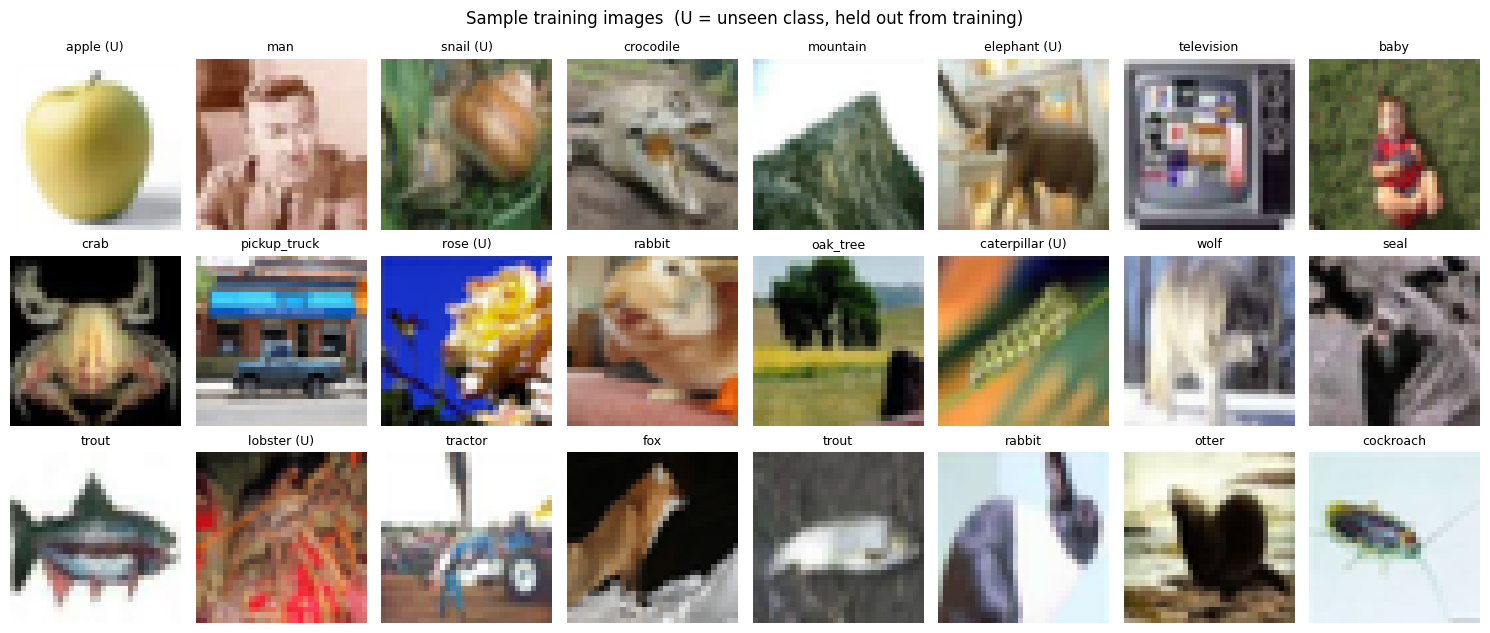

Images per class: min 500 max 500


In [4]:
# sample grid (U = unseen class) and class balance (uses the label array, no slow loop over transforms)
fig, axes = plt.subplots(3, 8, figsize=(15, 6.5))
for ax, i in zip(axes.flat, np.random.RandomState(0).choice(len(ytr), 24, replace=False)):
    ax.imshow(train_raw.data[i]); ax.axis("off")
    ax.set_title(class_names[ytr[i]] + (" (U)" if ytr[i] in unseen_classes else ""), fontsize=9)
plt.suptitle("Sample training images  (U = unseen class, held out from training)"); plt.tight_layout(); plt.show()

cnt = np.bincount(ytr)
print("Images per class: min", cnt.min(), "max", cnt.max())

## 3. GPU augmentation
Random crop with reflect padding, horizontal flip and cutout, all done in batch on the GPU.

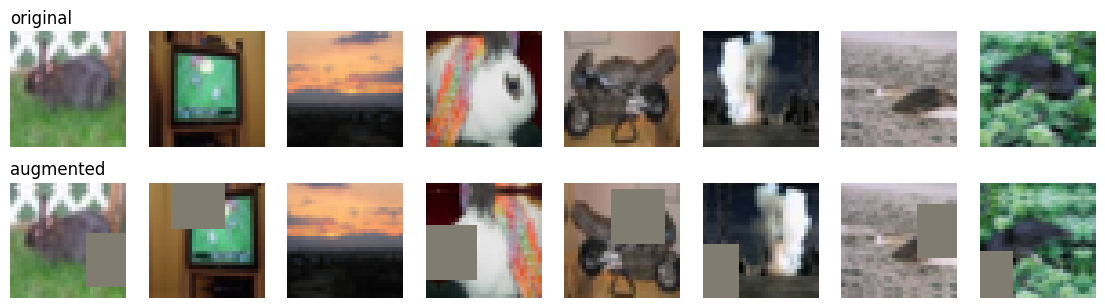

In [5]:
def to_input(xu8):                       # uint8 -> normalised float
    return ((xu8.float() / 255.0) - MEAN) / STD

def augment(x, cutout=True):             # x: normalised float batch, B x 3 x 32 x 32
    B, dev = x.size(0), x.device
    flip = torch.rand(B, device=dev) < 0.5
    x = torch.where(flip[:, None, None, None], x.flip(3), x)
    xp = F.pad(x, (4, 4, 4, 4), mode="reflect")
    i = torch.randint(0, 9, (B,), device=dev); j = torch.randint(0, 9, (B,), device=dev)
    ar = torch.arange(32, device=dev)
    rows = (i[:, None] + ar)[:, None, :, None]
    cols = (j[:, None] + ar)[:, None, None, :]
    bi = torch.arange(B, device=dev)[:, None, None, None]
    ci = torch.arange(3, device=dev)[None, :, None, None]
    x = xp[bi, ci, rows, cols]
    if cutout:
        cy = torch.randint(0, 32, (B, 1, 1), device=dev); cx = torch.randint(0, 32, (B, 1, 1), device=dev)
        m = ((ar[None, :, None] - cy).abs() < 8) & ((ar[None, None, :] - cx).abs() < 8) & (torch.rand(B, 1, 1, device=dev) < 0.5)
        x = x.masked_fill(m[:, None], 0.0)
    return x

xs = augment(to_input(Xfit[:8]))
fig, axes = plt.subplots(2, 8, figsize=(14, 3.6))
for k in range(8):
    axes[0, k].imshow(Xfit[k].permute(1, 2, 0).cpu()); axes[0, k].axis("off")
    axes[1, k].imshow((xs[k] * STD[0] + MEAN[0]).clamp(0, 1).permute(1, 2, 0).cpu()); axes[1, k].axis("off")
axes[0, 0].set_title("original", loc="left"); axes[1, 0].set_title("augmented", loc="left")
plt.show()

## 4. Models and losses

**Backbones**
* `baseline_cnn`: your original 4-conv-block CNN (Flatten, Linear, ReLU), adapted to native 32×32 input so it is a fair baseline.
* `resnet18`: CIFAR-style ResNet-18 (3×3 stem, no max-pool) with **global average pooling**, a linear embedding layer and BatchNorm. No ReLU on the embedding, so vectors can use the full cosine range. Embeddings are L2-normalised at retrieval time.

**Losses**
* `ce`: cross-entropy with label smoothing (classification only, no explicit control over distances).
* `arcface`: additive angular margin softmax, which forces tight, well-separated class clusters on the hypersphere.
* `supcon`: supervised contrastive loss on two augmented views.

In [6]:
class BaselineCNN(nn.Module):            # original architecture, native 32x32 input
    def __init__(self, emb_dim=256):
        super().__init__()
        def block(i, o): return [nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(), nn.MaxPool2d(2)]
        self.features = nn.Sequential(*block(3, 64), *block(64, 128), *block(128, 256), *block(256, 256))
        self.embed = nn.Sequential(nn.Flatten(), nn.Linear(256 * 2 * 2, emb_dim), nn.ReLU())
    def forward(self, x): return self.embed(self.features(x))

class BasicBlock(nn.Module):
    def __init__(self, cin, cout, stride):
        super().__init__()
        self.c1 = nn.Conv2d(cin, cout, 3, stride, 1, bias=False); self.b1 = nn.BatchNorm2d(cout)
        self.c2 = nn.Conv2d(cout, cout, 3, 1, 1, bias=False);     self.b2 = nn.BatchNorm2d(cout)
        self.short = nn.Identity() if (stride == 1 and cin == cout) else nn.Sequential(
            nn.Conv2d(cin, cout, 1, stride, bias=False), nn.BatchNorm2d(cout))
    def forward(self, x):
        o = F.relu(self.b1(self.c1(x)))
        o = self.b2(self.c2(o))
        return F.relu(o + self.short(x))

class ResNet18Embed(nn.Module):
    def __init__(self, emb_dim=256):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(3, 64, 3, 1, 1, bias=False), nn.BatchNorm2d(64), nn.ReLU())
        cfg, layers, cin = [(64, 1), (128, 2), (256, 2), (512, 2)], [], 64
        for cout, stride in cfg:
            layers += [BasicBlock(cin, cout, stride), BasicBlock(cout, cout, 1)]; cin = cout
        self.layers = nn.Sequential(*layers)
        self.fc = nn.Linear(512, emb_dim); self.bn = nn.BatchNorm1d(emb_dim)
    def forward(self, x):
        x = self.layers(self.stem(x))
        x = F.adaptive_avg_pool2d(x, 1).flatten(1)
        return self.bn(self.fc(x))

def build_model(arch, emb_dim):
    return {"baseline_cnn": BaselineCNN, "resnet18": ResNet18Embed}[arch](emb_dim)

# ---------------- heads / losses (all take raw embeddings + class-index labels, return a scalar loss)
class CEHead(nn.Module):
    def __init__(self, emb_dim, n_cls, ls):
        super().__init__(); self.fc = nn.Linear(emb_dim, n_cls); self.ls = ls
    def forward(self, emb, y): return F.cross_entropy(self.fc(emb), y, label_smoothing=self.ls)

class ArcFaceHead(nn.Module):
    def __init__(self, emb_dim, n_cls, s, m):
        super().__init__()
        self.W = nn.Parameter(torch.empty(n_cls, emb_dim)); nn.init.xavier_uniform_(self.W)
        self.s, self.m = s, m
        self.cos_m, self.sin_m = math.cos(m), math.sin(m)
        self.th, self.mm = math.cos(math.pi - m), math.sin(math.pi - m) * m
    def forward(self, emb, y):
        cos = F.linear(F.normalize(emb), F.normalize(self.W)).clamp(-1 + 1e-7, 1 - 1e-7)
        sin = (1 - cos ** 2).sqrt()
        phi = cos * self.cos_m - sin * self.sin_m
        phi = torch.where(cos > self.th, phi, cos - self.mm)
        onehot = F.one_hot(y, cos.size(1)).bool()
        return F.cross_entropy(torch.where(onehot, phi, cos) * self.s, y)

class SupConHead(nn.Module):
    def __init__(self, temp):
        super().__init__(); self.T = temp
    def forward(self, emb, y):
        if emb.size(0) == 2 * y.size(0): y = torch.cat([y, y])          # two views per image
        z = F.normalize(emb, dim=1)
        sim = z @ z.T / self.T
        eye = torch.eye(len(z), dtype=torch.bool, device=z.device)
        sim = sim.masked_fill(eye, -1e9)
        logp = sim - torch.logsumexp(sim, dim=1, keepdim=True)
        pos = (y[:, None] == y[None, :]) & ~eye
        return (-(logp * pos).sum(1) / pos.sum(1).clamp(min=1)).mean()

def build_head(loss_name, emb_dim, n_cls):
    if loss_name == "ce":      return CEHead(emb_dim, n_cls, CFG["label_smoothing"])
    if loss_name == "arcface": return ArcFaceHead(emb_dim, n_cls, CFG["arcface_s"], CFG["arcface_m"])
    if loss_name == "supcon":  return SupConHead(CFG["supcon_temp"])
    raise ValueError(loss_name)

for a in ("baseline_cnn", "resnet18"):
    print(f"{a}: {sum(p.numel() for p in build_model(a, CFG['emb_dim']).parameters()):,} parameters")

baseline_cnn: 1,224,704 parameters
resnet18: 11,300,672 parameters


## 5. Retrieval metrics (the core of the evaluation)

* **Recall@K** (hit rate): is at least one of the top-K results from the query's class?
* **Precision@K**: what fraction of the top-K results are from the query's class?
* **mAP@R**: the most informative single number. It rewards putting *all* relevant items at the top (R = number of relevant gallery items for that query).
* **Coarse** variants use the 20 CIFAR superclasses, where a "maple tree" result for an "oak tree" query counts as a hit.
* **kNN accuracy**: 20-nearest-neighbour majority vote on embeddings.

Everything runs exactly on the GPU with matrix multiplication (no approximation).

In [7]:
@torch.no_grad()
def embed_images(model, Xu8, bs=1024, tf=None):
    model.eval(); out = []
    for i in range(0, len(Xu8), bs):
        x = Xu8[i:i + bs].float() / 255.0
        if tf is not None: x = tf(x)
        x = (x - MEAN) / STD
        with torch.autocast("cuda", dtype=torch.float16, enabled=AMP):
            e = model(x)
        out.append(F.normalize(e.float(), dim=1))
    return torch.cat(out)

@torch.no_grad()
def retrieval_metrics(q, ql, g, gl, ks=(1, 5, 10), compute_map=True, chunk=1000):
    n_lab = int(max(ql.max(), gl.max())) + 1
    gcount = torch.bincount(gl, minlength=n_lab)
    Rmax = int(gcount[ql].max()) if compute_map else max(ks)
    Rmax = min(max(Rmax, max(ks)), len(g))
    rec = {k: 0.0 for k in ks}; prec = {k: 0.0 for k in ks}; ap_sum = 0.0
    pos_idx = torch.arange(Rmax, device=q.device)[None]
    for i in range(0, len(q), chunk):
        qq, qlab = q[i:i + chunk], ql[i:i + chunk]
        idx = (qq @ g.T).topk(Rmax, dim=1).indices
        hit = gl[idx] == qlab[:, None]
        for k in ks:
            rec[k] += hit[:, :k].any(1).sum().item()
            prec[k] += hit[:, :k].float().mean(1).sum().item()
        if compute_map:
            Rq = gcount[qlab]
            h = (hit & (pos_idx < Rq[:, None])).float()
            p_at = h.cumsum(1) / (pos_idx + 1)
            ap_sum += ((p_at * h).sum(1) / Rq.clamp(min=1)).sum().item()
    n = len(q)
    out = {}
    for k in ks: out[f"R@{k}"] = rec[k] / n
    for k in ks: out[f"P@{k}"] = prec[k] / n
    if compute_map: out["mAP@R"] = ap_sum / n
    return out

@torch.no_grad()
def knn_accuracy(q, ql, g, gl, k=20, chunk=1000):
    correct = 0
    for i in range(0, len(q), chunk):
        idx = (q[i:i + chunk] @ g.T).topk(k, dim=1).indices
        votes = F.one_hot(gl[idx], 100).sum(1)
        correct += (votes.argmax(1) == ql[i:i + chunk]).sum().item()
    return correct / len(q)

def eval_split(Etr, Ete, g_idx, q_idx):
    g, q, gl, ql = Etr[g_idx], Ete[q_idx], ytr_g[g_idx], yte_g[q_idx]
    m = retrieval_metrics(q, ql, g, gl)
    mc = retrieval_metrics(q, COARSE_g[ql], g, COARSE_g[gl], compute_map=False)
    m.update({"coarse_" + k: v for k, v in mc.items()})
    m["kNN20"] = knn_accuracy(q, ql, g, gl)
    return m

def eval_splits(Etr, Ete):
    return {"seen": eval_split(Etr, Ete, G_SEEN_t, Q_SEEN_t),
            "unseen": eval_split(Etr, Ete, G_UNSEEN_t, Q_UNSEEN_t)}

def results_table(res):
    rows = []
    for name, r in res.items():
        row = {"model": name}
        for sp in ("seen", "unseen"):
            for key, lab in (("R@1", "R@1"), ("R@5", "R@5"), ("mAP@R", "mAP@R"), ("coarse_R@1", "coarse R@1")):
                row[f"{sp} {lab}"] = r[sp][key]
        rows.append(row)
    return pd.DataFrame(rows).set_index("model")

def val_score(model):                      # validation (seen classes only): val images vs fit images
    g, q = embed_images(model, Xfit), embed_images(model, Xval)
    m = retrieval_metrics(q, yval_o, g, yfit_o, ks=(1, 5))
    return m["mAP@R"], m["R@1"]

## 6. Training loop
AdamW, one-cycle learning-rate schedule, mixed precision, GPU augmentation. The checkpoint is chosen by **validation mAP@R**, never by test.

In [8]:
def train_model(arch, loss_name, seed, epochs=None, verbose=True):
    epochs = epochs or CFG["epochs"]; bs = CFG["batch_size"]
    set_seed(seed)
    model = build_model(arch, CFG["emb_dim"]).to(DEVICE)
    head = build_head(loss_name, CFG["emb_dim"], N_CLS).to(DEVICE)
    params = list(model.parameters()) + list(head.parameters())
    opt = torch.optim.AdamW(params, lr=CFG["lr"], weight_decay=CFG["weight_decay"])
    steps = len(Xfit) // bs
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=CFG["lr"], total_steps=epochs * steps, pct_start=0.2)
    scaler = torch.amp.GradScaler("cuda", enabled=AMP)

    hist = dict(epoch=[], loss=[], val_map=[], val_r1=[], val_epoch=[])
    best_map, best_state, best_ep = -1.0, None, -1
    t0 = time.time()
    pbar = tqdm(range(epochs), desc=f"{arch}+{loss_name} (seed {seed})", disable=not verbose)
    for ep in pbar:
        model.train(); head.train()
        order = torch.randperm(len(Xfit), device=DEVICE); run = 0.0
        for it in range(steps):
            b = order[it * bs:(it + 1) * bs]
            xb, yb = Xfit[b], yfit_c[b]
            with torch.autocast("cuda", dtype=torch.float16, enabled=AMP):
                if loss_name == "supcon":
                    x = torch.cat([augment(to_input(xb)), augment(to_input(xb))])
                else:
                    x = augment(to_input(xb))
                emb = model(x)
            loss = head(emb.float(), yb)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
            run += loss.item()
        hist["epoch"].append(ep + 1); hist["loss"].append(run / steps)
        if (ep + 1) % CFG["eval_every"] == 0 or ep == epochs - 1:
            vm, vr = val_score(model)
            hist["val_map"].append(vm); hist["val_r1"].append(vr); hist["val_epoch"].append(ep + 1)
            if vm > best_map:
                best_map, best_ep, best_state = vm, ep + 1, copy.deepcopy(model.state_dict())
            pbar.set_postfix(loss=f"{run/steps:.3f}", val_mAP=f"{vm:.3f}", val_R1=f"{vr:.3f}")
    model.load_state_dict(best_state)
    hist.update(best_val_map=best_map, best_epoch=best_ep, train_minutes=(time.time() - t0) / 60)
    return model, hist

## 7. Ablation: backbone and loss

Four models trained under identical conditions (same data, augmentation, schedule, seed). Differences in the table are therefore caused by the architecture or loss only.

In [9]:
EXPERIMENTS = [("baseline_cnn", "ce"), ("resnet18", "ce"), ("resnet18", "arcface"), ("resnet18", "supcon")]
NAME2CFG = {f"{a}+{l}": (a, l) for a, l in EXPERIMENTS}

trained, histories, results, EMB = {}, {}, {}, {}
for name, (arch, loss_name) in NAME2CFG.items():
    model, hist = train_model(arch, loss_name, seed=CFG["ablation_seed"])
    Etr, Ete = embed_images(model, Xtr_g), embed_images(model, Xte_g)
    trained[name], histories[name], EMB[name] = model, hist, (Etr, Ete)
    results[name] = eval_splits(Etr, Ete)          # test set used here only for REPORTING
    torch.save({"model_state_dict": model.state_dict(), "arch": arch, "loss": loss_name, "config": CFG,
                "seen_classes": seen_classes, "unseen_classes": unseen_classes, "class_names": class_names,
                "best_val_mAP@R": hist["best_val_map"], "best_epoch": hist["best_epoch"]},
               f"ckpt_{name}.pth")
    print(f"{name}: best epoch {hist['best_epoch']} | val mAP@R {hist['best_val_map']:.4f} | "
          f"{hist['train_minutes']:.1f} min | test seen R@1 {results[name]['seen']['R@1']:.4f} | "
          f"unseen R@1 {results[name]['unseen']['R@1']:.4f}")

display(results_table(results).round(4))

baseline_cnn+ce (seed 0):   0%|          | 0/30 [00:00<?, ?it/s]

baseline_cnn+ce: best epoch 30 | val mAP@R 0.2021 | 1.8 min | test seen R@1 0.6259 | unseen R@1 0.6445


resnet18+ce (seed 0):   0%|          | 0/30 [00:00<?, ?it/s]

resnet18+ce: best epoch 30 | val mAP@R 0.5320 | 8.6 min | test seen R@1 0.7465 | unseen R@1 0.6690


resnet18+arcface (seed 0):   0%|          | 0/30 [00:00<?, ?it/s]

/tmp/ipykernel_1429/3071766963.py:30: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()


resnet18+arcface: best epoch 6 | val mAP@R 0.1082 | 8.5 min | test seen R@1 0.4580 | unseen R@1 0.5070


resnet18+supcon (seed 0):   0%|          | 0/30 [00:00<?, ?it/s]

resnet18+supcon: best epoch 30 | val mAP@R 0.6555 | 15.1 min | test seen R@1 0.7372 | unseen R@1 0.5550


,seen R@1,seen R@5,seen mAP@R,seen coarse R@1,unseen R@1,unseen R@5,unseen mAP@R,unseen coarse R@1
model,,,,,,,,
baseline_cnn+ce,0.6259,0.8070,0.2055,0.7508,0.6445,0.8775,0.1513,0.682
resnet18+ce,0.7465,0.8486,0.5187,0.8404,0.6690,0.8735,0.1569,0.709
resnet18+arcface,0.4580,0.6740,0.1110,0.5915,0.5070,0.7870,0.0923,0.553
resnet18+supcon,0.7372,0.8356,0.6472,0.8484,0.5550,0.8040,0.1774,0.629


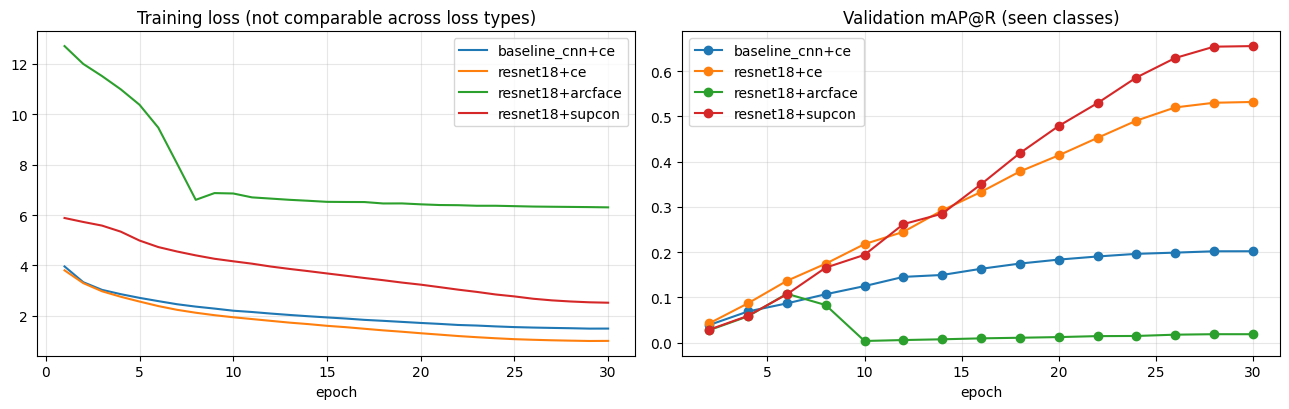

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for name, h in histories.items():
    axes[0].plot(h["epoch"], h["loss"], label=name)
    axes[1].plot(h["val_epoch"], h["val_map"], marker="o", label=name)
axes[0].set_title("Training loss (not comparable across loss types)"); axes[0].set_xlabel("epoch")
axes[1].set_title("Validation mAP@R (seen classes)"); axes[1].set_xlabel("epoch")
for a in axes: a.grid(alpha=0.3); a.legend()
plt.tight_layout(); plt.show()

## 8. Pretrained baselines (frozen)

Frozen ImageNet ResNet-50 and DINOv2 ViT-S/14, CIFAR images upsampled to 224×224, no fine-tuning. This answers: *how good is a from-scratch model compared with off-the-shelf features?*

**Caveat to state honestly:** these models saw ImageNet, which overlaps heavily with CIFAR-style categories, so their "unseen" column is not truly unseen. Your own models' unseen column is.

In [11]:
IM_MEAN = torch.tensor([0.485, 0.456, 0.406], device=DEVICE).view(1, 3, 1, 1)
IM_STD  = torch.tensor([0.229, 0.224, 0.225], device=DEVICE).view(1, 3, 1, 1)

@torch.no_grad()
def extract_pretrained(net, Xu8, size=224, bs=250):
    net = net.eval().to(DEVICE); out = []
    for i in tqdm(range(0, len(Xu8), bs), leave=False):
        x = F.interpolate(Xu8[i:i + bs].float() / 255.0, size=(size, size), mode="bilinear", align_corners=False)
        x = (x - IM_MEAN) / IM_STD
        with torch.autocast("cuda", dtype=torch.float16, enabled=AMP):
            e = net(x)
        out.append(F.normalize(e.float(), dim=1))
    return torch.cat(out)

pretrained_results = {}
def add_pretrained(name, net):
    Etr_p, Ete_p = extract_pretrained(net, Xtr_g), extract_pretrained(net, Xte_g)
    pretrained_results[name] = eval_splits(Etr_p, Ete_p)
    print(f"{name}: dim {Etr_p.shape[1]} | seen R@1 {pretrained_results[name]['seen']['R@1']:.4f}")

try:
    r50 = models.resnet50(weights="IMAGENET1K_V2"); r50.fc = nn.Identity()
    add_pretrained("pretrained ResNet-50 (frozen)", r50); del r50
except Exception as e:
    print("ResNet-50 baseline skipped:", e)

try:
    dino = torch.hub.load("facebookresearch/dinov2", "dinov2_vits14")
    add_pretrained("pretrained DINOv2-S/14 (frozen)", dino); del dino
except Exception as e:
    print("DINOv2 baseline skipped:", e)

torch.cuda.empty_cache()
all_results = {**results, **pretrained_results}
final_df = results_table(all_results)
display(final_df.round(4))

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 177MB/s]


  0%|          | 0/200 [00:00<?, ?it/s]

  0%|          | 0/40 [00:00<?, ?it/s]

pretrained ResNet-50 (frozen): dim 2048 | seen R@1 0.6546
Downloading: "https://github.com/facebookresearch/dinov2/zipball/main" to /root/.cache/torch/hub/main.zip


/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")


... (2 outputs left out)

  0%|          | 0/200 [00:00<?, ?it/s]

  0%|          | 0/40 [00:00<?, ?it/s]

pretrained DINOv2-S/14 (frozen): dim 384 | seen R@1 0.7810


,seen R@1,seen R@5,seen mAP@R,seen coarse R@1,unseen R@1,unseen R@5,unseen mAP@R,unseen coarse R@1
model,,,,,,,,
baseline_cnn+ce,0.6259,0.8070,0.2055,0.7508,0.6445,0.8775,0.1513,0.6820
resnet18+ce,0.7465,0.8486,0.5187,0.8404,0.6690,0.8735,0.1569,0.7090
resnet18+arcface,0.4580,0.6740,0.1110,0.5915,0.5070,0.7870,0.0923,0.5530
resnet18+supcon,0.7372,0.8356,0.6472,0.8484,0.5550,0.8040,0.1774,0.6290
pretrained ResNet-50 (frozen),0.6546,0.8495,0.1495,0.7789,0.7860,0.9340,0.2763,0.8070
pretrained DINOv2-S/14 (frozen),0.7810,0.9194,0.2750,0.8706,0.8875,0.9675,0.4344,0.8955


## 9. Seeds: mean ± std for the best method

The best method is chosen by **validation** mAP@R (not test). It is then retrained with extra seeds so you can report variance instead of one lucky run.

In [12]:
best_name = max(histories, key=lambda n: histories[n]["best_val_map"])
arch_b, loss_b = NAME2CFG[best_name]
print("Best by validation mAP@R:", best_name, f"({histories[best_name]['best_val_map']:.4f})")

seed_results = {CFG["ablation_seed"]: results[best_name]}
for s in CFG["extra_seeds"]:
    m, h = train_model(arch_b, loss_b, seed=s)
    seed_results[s] = eval_splits(embed_images(m, Xtr_g), embed_images(m, Xte_g))
    del m; torch.cuda.empty_cache()

rows = []
for sp in ("seen", "unseen"):
    for key in ("R@1", "R@5", "mAP@R", "coarse_R@1"):
        v = np.array([seed_results[s][sp][key] for s in seed_results])
        rows.append({"split": sp, "metric": key, "mean": v.mean(), "std": v.std(ddof=1) if len(v) > 1 else float("nan"), "runs": len(v)})
seed_df = pd.DataFrame(rows)
print(f"\n{best_name}: results over {len(seed_results)} training seed(s)")
display(seed_df.round(4))

Best by validation mAP@R: resnet18+supcon (0.6555)


resnet18+supcon (seed 1):   0%|          | 0/30 [00:00<?, ?it/s]

resnet18+supcon (seed 2):   0%|          | 0/30 [00:00<?, ?it/s]


resnet18+supcon: results over 3 training seed(s)


,split,metric,mean,std,runs
0,seen,R@1,0.7341,0.0038,3
1,seen,R@5,0.8315,0.0036,3
2,seen,mAP@R,0.6419,0.0046,3
3,seen,coarse_R@1,0.8447,0.0040,3
4,unseen,R@1,0.5477,0.0075,3
5,unseen,R@5,0.8010,0.0048,3
6,unseen,mAP@R,0.1754,0.0020,3
7,unseen,coarse_R@1,0.6230,0.0063,3


## 10. Embedding-space validation (quantitative and visual)

A t-SNE picture alone is not evidence, so it is paired with numbers: kNN accuracy and cosine silhouette score. The t-SNE shows 10 **randomly chosen** classes (not the first 10 alphabetically), once for seen classes and once for **unseen** classes.

Silhouette (cosine)  seen test: 0.358 | unseen test: 0.014
kNN-20 accuracy      seen: 0.757 | unseen: 0.580


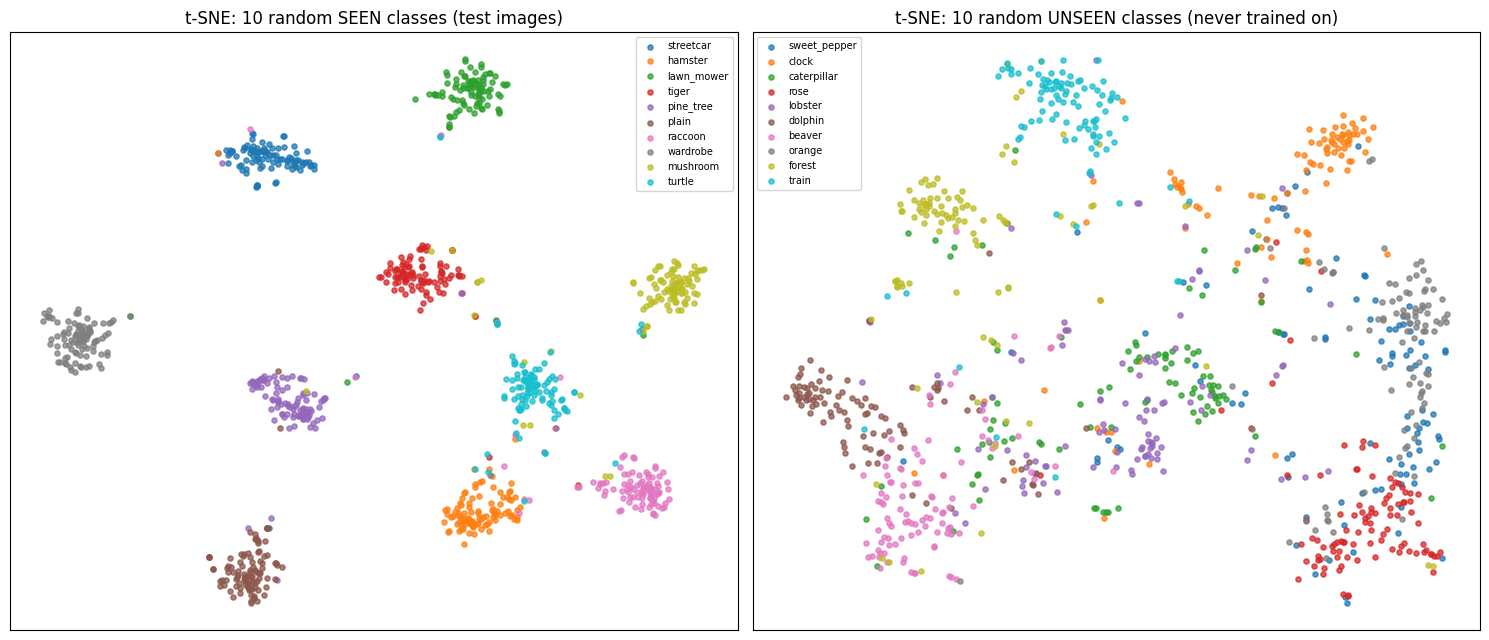

In [13]:
best_model = trained[best_name]
Etr_best, Ete_best = EMB[best_name]

def emb_quality(Ete, q_idx):
    e = Ete[q_idx].cpu().numpy(); y = yte[q_idx.cpu().numpy()]
    return silhouette_score(e, y, metric="cosine", sample_size=min(3000, len(y)), random_state=0)

print(f"Silhouette (cosine)  seen test: {emb_quality(Ete_best, Q_SEEN_t):.3f} | unseen test: {emb_quality(Ete_best, Q_UNSEEN_t):.3f}")
print(f"kNN-20 accuracy      seen: {results[best_name]['seen']['kNN20']:.3f} | unseen: {results[best_name]['unseen']['kNN20']:.3f}")

def plot_tsne(ax, classes, title, per_class=100):
    sel = np.concatenate([np.where(yte == c)[0][:per_class] for c in classes])
    z = TSNE(n_components=2, init="pca", perplexity=30, random_state=0).fit_transform(Ete_best[to_t(sel)].cpu().numpy())
    cmap = plt.get_cmap("tab10")
    for k, c in enumerate(classes):
        m = yte[sel] == c
        ax.scatter(z[m, 0], z[m, 1], s=14, alpha=0.75, color=cmap(k), label=class_names[c])
    ax.set_title(title); ax.legend(fontsize=7, loc="best"); ax.set_xticks([]); ax.set_yticks([])

r = np.random.RandomState(1)
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
plot_tsne(axes[0], r.choice(seen_classes, 10, replace=False), "t-SNE: 10 random SEEN classes (test images)")
plot_tsne(axes[1], r.choice(unseen_classes, 10, replace=False), "t-SNE: 10 random UNSEEN classes (never trained on)")
plt.tight_layout(); plt.show()

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


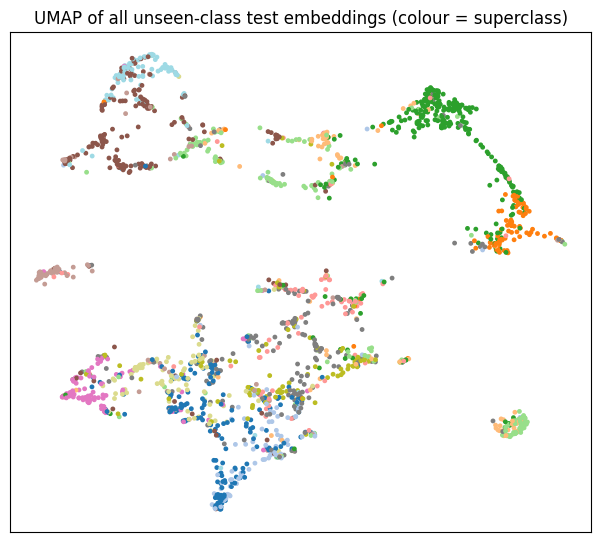

In [14]:
# Optional: UMAP view of all unseen classes (preserves global structure better than t-SNE)
try:
    import umap
    z = umap.UMAP(n_neighbors=15, min_dist=0.1, metric="cosine", random_state=0).fit_transform(Ete_best[Q_UNSEEN_t].cpu().numpy())
    plt.figure(figsize=(7.5, 6.5))
    plt.scatter(z[:, 0], z[:, 1], c=COARSE[yte[te_unseen]], cmap="tab20", s=6)
    plt.title("UMAP of all unseen-class test embeddings (colour = superclass)"); plt.xticks([]); plt.yticks([]); plt.show()
except Exception as e:
    print("UMAP skipped:", e)

## 11. Error analysis
Which classes fail, which pairs get confused, and are the mistakes at least *semantically close* (same superclass)?

Worst 12 classes (1-NN accuracy):
  boy              0.34
  seal             0.36
  otter            0.39
  girl             0.42
  woman            0.44
  man              0.46
  mouse            0.47
  possum           0.53
  bear             0.54
  shrew            0.57
  rabbit           0.57
  baby             0.59
Best 5: [('mountain', 0.94), ('sunflower', 0.93), ('tractor', 0.93), ('road', 0.93), ('motorcycle', 0.93)]

Top confusions (true -> predicted):
  seal           -> otter          x27   (same superclass)
  otter          -> seal           x20   (same superclass)
  boy            -> girl           x19   (same superclass)
  maple_tree     -> oak_tree       x19   (same superclass)
  woman          -> girl           x19   (same superclass)
  girl           -> boy            x18   (same superclass)
  oak_tree       -> pine_tree      x18   (same superclass)
  boy            -> baby           x17   (same superclass)
  man            -> boy            x17   (same superclass)
  b

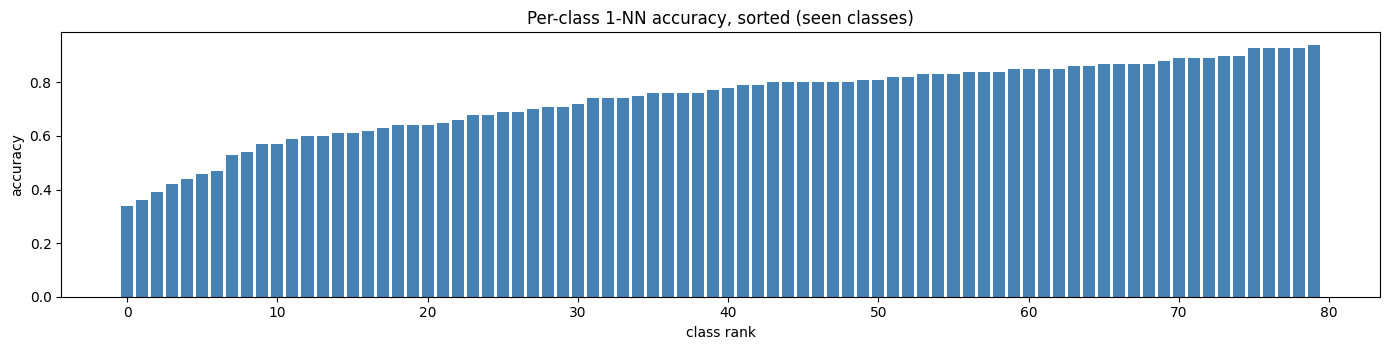

In [15]:
@torch.no_grad()
def top1(q, g, chunk=2000):
    vals, idxs = [], []
    for i in range(0, len(q), chunk):
        v, ix = (q[i:i + chunk] @ g.T).max(1); vals.append(v); idxs.append(ix)
    return torch.cat(vals), torch.cat(idxs)

q, g = Ete_best[Q_SEEN_t], Etr_best[G_SEEN_t]
true, gl = yte_g[Q_SEEN_t], ytr_g[G_SEEN_t]
sims1, nn1 = top1(q, g)
pred = gl[nn1]; wrong = (pred != true).nonzero().squeeze(1)

# per-class 1-NN accuracy
corr = torch.bincount(true[pred == true], minlength=100).float(); tot = torch.bincount(true, minlength=100).float()
acc = (corr / tot.clamp(min=1)).cpu().numpy()
order = [c for c in np.argsort(acc) if c in seen_classes]
print("Worst 12 classes (1-NN accuracy):")
for c in order[:12]: print(f"  {class_names[c]:<16} {acc[c]:.2f}")
print("Best 5:", [(class_names[c], round(float(acc[c]), 2)) for c in order[::-1][:5]])

# most common confusions + how many errors stay inside the same superclass
tt, pp = true[wrong].cpu().numpy(), pred[wrong].cpu().numpy()
print("\nTop confusions (true -> predicted):")
for (a, b), n in Counter(zip(tt.tolist(), pp.tolist())).most_common(12):
    print(f"  {class_names[a]:<14} -> {class_names[b]:<14} x{n}   {'(same superclass)' if COARSE[a] == COARSE[b] else ''}")
print(f"\nErrors that stay inside the correct superclass: {(COARSE[tt] == COARSE[pp]).mean():.1%}  (these are 'near misses')")

plt.figure(figsize=(14, 3.6))
plt.bar(range(len(seen_classes)), np.sort(acc[seen_classes]), color="steelblue")
plt.title("Per-class 1-NN accuracy, sorted (seen classes)"); plt.xlabel("class rank"); plt.ylabel("accuracy"); plt.tight_layout(); plt.show()

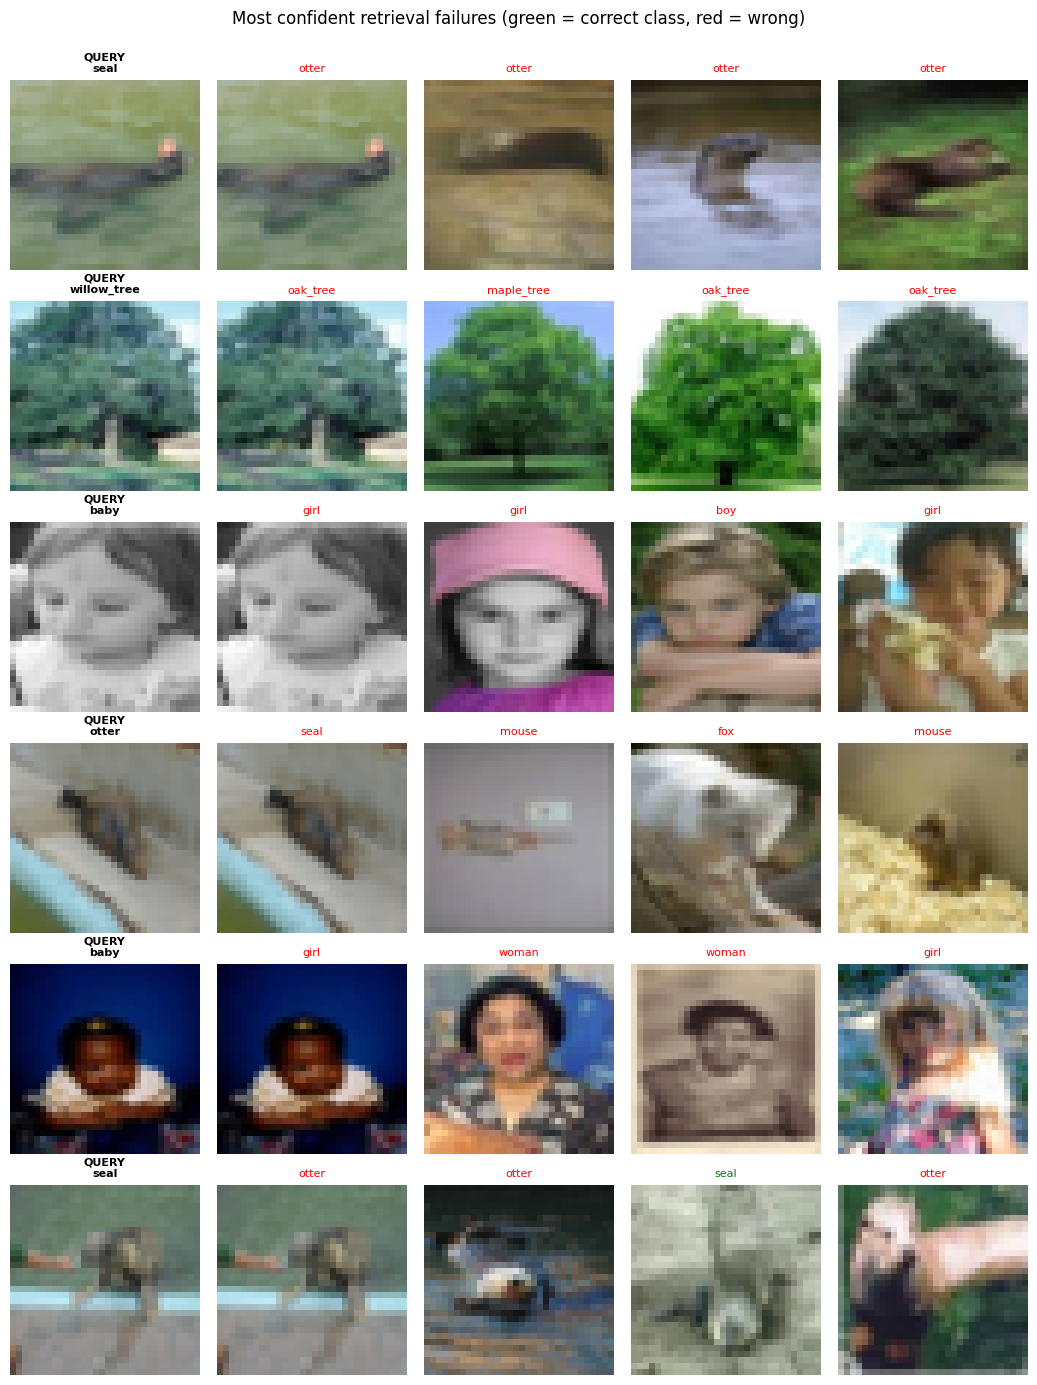

In [16]:
def img_np(t): return t.permute(1, 2, 0).cpu().numpy()

def show_failures(n=6, k=4):
    # the most CONFIDENT mistakes: wrong top-1 with the highest similarity score
    sel = wrong[sims1[wrong].argsort(descending=True)[:n]]
    fig, axes = plt.subplots(n, k + 1, figsize=(2.1 * (k + 1), 2.3 * n))
    for r_, qi in enumerate(sel.tolist()):
        top = (q[qi:qi + 1] @ g.T).topk(k).indices[0].tolist()
        axes[r_, 0].imshow(img_np(Xte_g[Q_SEEN_t[qi]])); axes[r_, 0].set_title("QUERY\n" + class_names[true[qi]], fontsize=8, fontweight="bold")
        for c_, gi in enumerate(top):
            ok = gl[gi] == true[qi]
            axes[r_, c_ + 1].imshow(img_np(Xtr_g[G_SEEN_t[gi]]))
            axes[r_, c_ + 1].set_title(class_names[gl[gi]], fontsize=8, color="green" if ok else "red")
    for a in axes.flat: a.axis("off")
    plt.suptitle("Most confident retrieval failures (green = correct class, red = wrong)", y=1.0); plt.tight_layout(); plt.show()

show_failures()

## 12. "No good match" detection (open-set rejection)

The model is trained on 80 classes, so a query of something outside them (or your own photo) still returns *some* neighbours. A similarity threshold lets the system say "no confident match". Here we measure how well the top-1 similarity separates **seen-class queries** (should match) from **unseen-class queries** (should be rejected).

AUROC (top-1 similarity, seen vs unseen): 0.756
Threshold 0.840 accepts 95% of seen queries and rejects 19.7% of unseen queries


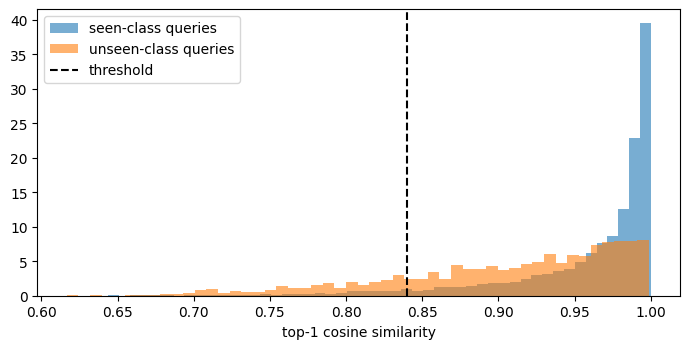

In [17]:
s_in, _  = top1(Ete_best[Q_SEEN_t],   Etr_best[G_SEEN_t])
s_out, _ = top1(Ete_best[Q_UNSEEN_t], Etr_best[G_SEEN_t])
s_in, s_out = s_in.cpu().numpy(), s_out.cpu().numpy()
auroc = roc_auc_score(np.r_[np.ones_like(s_in), np.zeros_like(s_out)], np.r_[s_in, s_out])
OOD_THR = float(np.percentile(s_in, 5))                 # keeps 95% of in-distribution queries
print(f"AUROC (top-1 similarity, seen vs unseen): {auroc:.3f}")
print(f"Threshold {OOD_THR:.3f} accepts 95% of seen queries and rejects {(s_out < OOD_THR).mean():.1%} of unseen queries")

plt.figure(figsize=(7, 3.6))
plt.hist(s_in, bins=50, alpha=0.6, label="seen-class queries", density=True)
plt.hist(s_out, bins=50, alpha=0.6, label="unseen-class queries", density=True)
plt.axvline(OOD_THR, color="k", ls="--", label="threshold"); plt.xlabel("top-1 cosine similarity"); plt.legend(); plt.tight_layout(); plt.show()

## 13. Robustness to image corruptions
Queries are perturbed (noise, blur, brightness, zoom crop), the gallery stays clean. The plot shows how fast seen-class Recall@1 drops. Models with better embeddings usually degrade more gracefully.

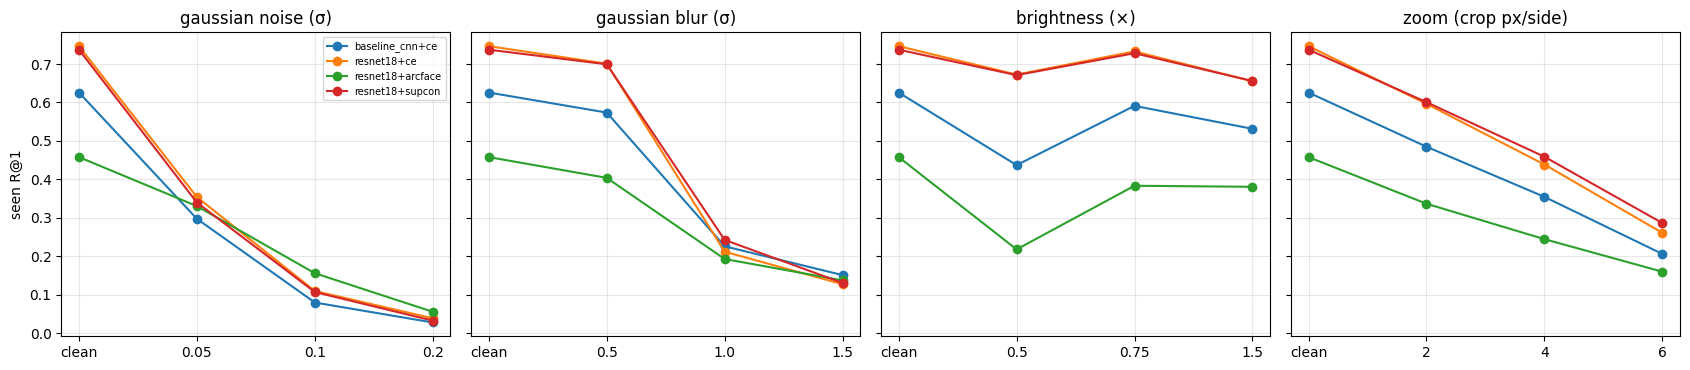

In [18]:
CONDS = {
    "gaussian noise (σ)":  ([0.05, 0.1, 0.2],  lambda s: (lambda x: (x + torch.randn_like(x) * s).clamp(0, 1))),
    "gaussian blur (σ)":   ([0.5, 1.0, 1.5],   lambda s: (lambda x: TF.gaussian_blur(x, kernel_size=5, sigma=s))),
    "brightness (×)":      ([0.5, 0.75, 1.5],  lambda s: (lambda x: (x * s).clamp(0, 1))),
    "zoom (crop px/side)": ([2, 4, 6],         lambda c: (lambda x: F.interpolate(x[:, :, c:32 - c, c:32 - c], size=(32, 32), mode="bilinear", align_corners=False))),
}
Xq_seen = Xte_g[Q_SEEN_t]
rob = {n: {} for n in trained}
for n, m in trained.items():
    g_ = EMB[n][0][G_SEEN_t]
    for cname, (levels, mk) in CONDS.items():
        vals = [0.0] + []
        r1 = []
        for lv in [None] + levels:
            torch.manual_seed(0)
            e = embed_images(m, Xq_seen, tf=None if lv is None else mk(lv))
            r1.append(retrieval_metrics(e, yte_g[Q_SEEN_t], g_, ytr_g[G_SEEN_t], ks=(1,), compute_map=False)["R@1"])
        rob[n][cname] = r1

fig, axes = plt.subplots(1, 4, figsize=(17, 3.8), sharey=True)
for ax, (cname, (levels, _)) in zip(axes, CONDS.items()):
    for n in trained: ax.plot(["clean"] + [str(l) for l in levels], rob[n][cname], marker="o", label=n)
    ax.set_title(cname); ax.grid(alpha=0.3)
axes[0].set_ylabel("seen R@1"); axes[0].legend(fontsize=7); plt.tight_layout(); plt.show()

## 14. FAISS index benchmark: accuracy vs speed vs memory
Exact search (`Flat`) is perfect but scales linearly. Approximate indexes trade a little recall for large speed and memory gains. This benchmark uses the full 50k-image gallery and 10k queries. "Recall@10 vs exact" is the fraction of the true top-10 neighbours the index finds.

,build_s,ms_per_query,recall10_vs_exact,label_R1,memory_MB
index,,,,,
Flat (exact),0.0000,0.2789,1.0000,0.6160,51.2000
HNSW32 ef=16,3.9048,0.0538,0.9749,0.6151,64.8126
HNSW32 ef=64,3.9048,0.1137,0.9928,0.6155,64.8126
IVF256 nprobe=1,0.8955,0.0272,0.7545,0.6050,51.8643
IVF256 nprobe=8,0.8955,0.0821,0.9872,0.6161,51.8643
IVF256 nprobe=32,0.8955,0.2386,0.9993,0.6162,51.8643
IVF256-PQ16 nprobe=8,44.6490,0.0849,0.6211,0.6009,1.7265
IVF256-PQ16 nprobe=32,44.6490,0.1901,0.6217,0.6010,1.7265


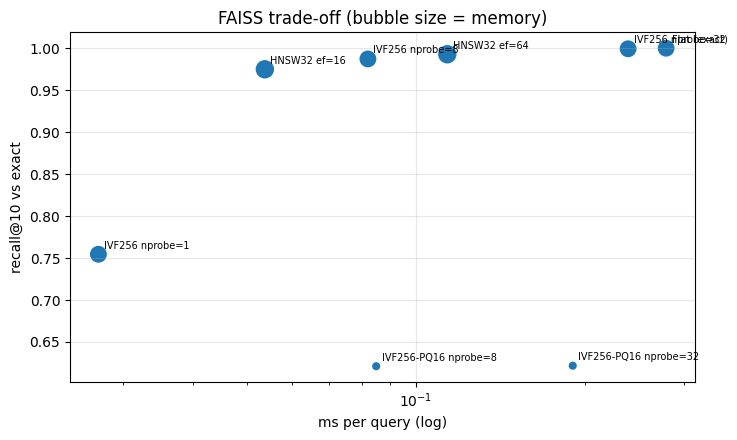

In [19]:
xb = Etr_best.cpu().numpy().astype("float32"); xq = Ete_best.cpu().numpy().astype("float32"); d = xb.shape[1]
ps = faiss.ParameterSpace()

flat = faiss.IndexFlatL2(d); flat.add(xb)               # L2 on unit vectors gives the same ranking as cosine
_, I_exact = flat.search(xq, 10)

def run(label, index, param=None, value=None, build_s=0.0):
    if param: ps.set_index_parameter(index, param, value)
    t = time.perf_counter(); _, I = index.search(xq, 10); lat = (time.perf_counter() - t) / len(xq) * 1000
    rec10 = np.mean([len(set(I[i]) & set(I_exact[i])) / 10 for i in range(len(xq))])
    r1 = (ytr[I[:, 0]] == yte).mean()
    mem = len(faiss.serialize_index(index)) / 1e6
    return dict(index=label, build_s=build_s, ms_per_query=lat, recall10_vs_exact=rec10, label_R1=r1, memory_MB=mem)

rows = [run("Flat (exact)", flat)]
t = time.perf_counter(); hn = faiss.index_factory(d, "HNSW32"); hn.add(xb); bt = time.perf_counter() - t
for ef in (16, 64): rows.append(run(f"HNSW32 ef={ef}", hn, "efSearch", ef, bt))
t = time.perf_counter(); ivf = faiss.index_factory(d, "IVF256,Flat"); ivf.train(xb); ivf.add(xb); bt = time.perf_counter() - t
for npb in (1, 8, 32): rows.append(run(f"IVF256 nprobe={npb}", ivf, "nprobe", npb, bt))
t = time.perf_counter(); pq = faiss.index_factory(d, "IVF256,PQ16"); pq.train(xb); pq.add(xb); bt = time.perf_counter() - t
for npb in (8, 32): rows.append(run(f"IVF256-PQ16 nprobe={npb}", pq, "nprobe", npb, bt))

faiss_df = pd.DataFrame(rows).set_index("index"); display(faiss_df.round(4))

plt.figure(figsize=(7.5, 4.5))
plt.scatter(faiss_df["ms_per_query"], faiss_df["recall10_vs_exact"], s=faiss_df["memory_MB"] * 2 + 20)
for n, r_ in faiss_df.iterrows(): plt.annotate(n, (r_["ms_per_query"], r_["recall10_vs_exact"]), fontsize=7, xytext=(4, 4), textcoords="offset points")
plt.xscale("log"); plt.xlabel("ms per query (log)"); plt.ylabel("recall@10 vs exact"); plt.title("FAISS trade-off (bubble size = memory)"); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

## 15. Inspect one embedding, then search with your own image

CIFAR images are 32×32, so photos are center-cropped and downscaled to 32×32. Expect weaker results on real photos (domain shift). The threshold from section 12 flags "no confident match".

In [20]:
x0 = Xte_g[7:8]
e0 = embed_images(best_model, x0)[0].cpu().numpy()
print("Embedding shape:", e0.shape, "| L2 norm:", round(float(np.linalg.norm(e0)), 4))
print("First 10 values:", np.round(e0[:10], 4))

Embedding shape: (256,) | L2 norm: 1.0
First 10 values: [ 4.890e-02 -5.600e-03  1.930e-02  1.032e-01  1.900e-03 -9.270e-02
  6.050e-02 -5.370e-02 -1.000e-04  1.130e-02]


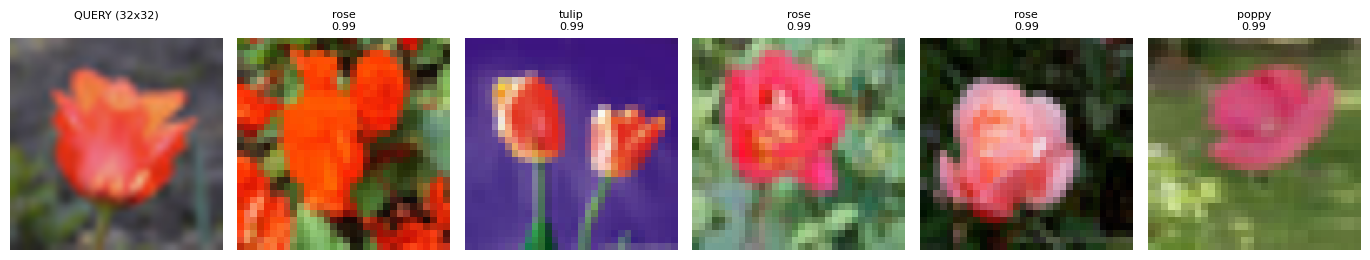

Saving Screenshot 2026-10-30 221933.png to Screenshot 2026-10-30 221933.png


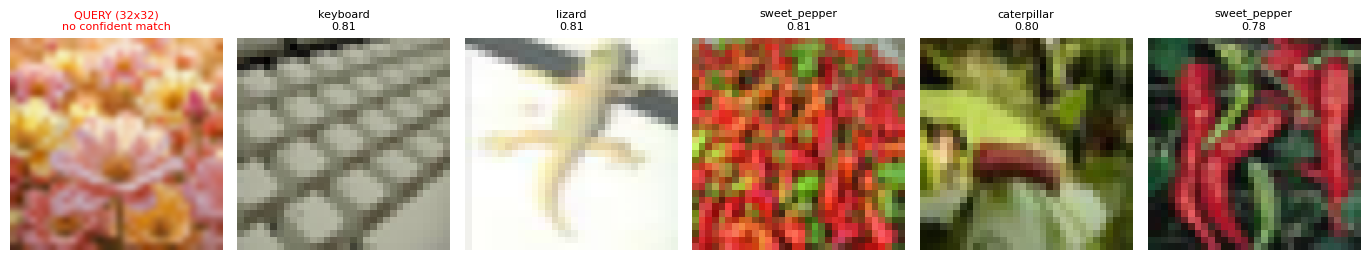

In [21]:
from PIL import Image

flat_cos = faiss.IndexFlatIP(d); flat_cos.add(xb)       # cosine search over the whole 50k gallery

def search_pil(img, k=5):
    img = img.convert("RGB"); w, h = img.size; s = min(w, h)
    img = img.crop(((w - s) // 2, (h - s) // 2, (w + s) // 2, (h + s) // 2)).resize((32, 32), Image.BICUBIC)
    x = torch.from_numpy(np.array(img)).permute(2, 0, 1)[None].to(DEVICE)
    qv = embed_images(best_model, x).cpu().numpy().astype("float32")
    sc, ids = flat_cos.search(qv, k)
    return img, sc[0], ids[0]

def show_search(img, k=5):
    q_img, sc, ids = search_pil(img, k)
    confident = sc[0] >= OOD_THR
    fig, axes = plt.subplots(1, k + 1, figsize=(2.3 * (k + 1), 2.8))
    axes[0].imshow(q_img.resize((128, 128))); axes[0].set_title("QUERY (32x32)\n" + ("" if confident else "no confident match"), fontsize=8,
                                                               color="black" if confident else "red")
    for a, (s_, i_) in zip(axes[1:], zip(sc, ids)):
        a.imshow(train_raw.data[i_]); a.set_title(f"{class_names[ytr[i_]]}\n{s_:.2f}", fontsize=8)
    for a in axes: a.axis("off")
    plt.tight_layout(); plt.show()

# demo with a test image
show_search(Image.fromarray(test_raw.data[123]))

# upload your own (Colab only)
try:
    from google.colab import files
    up = files.upload()
    for fn in up: show_search(Image.open(fn))
except Exception as e:
    print("Upload skipped:", e)

## 16. Save everything
Checkpoint with config, class split and metrics, embeddings, FAISS index, ONNX export, and a results JSON. The test metrics inside the checkpoint come from the **single final evaluation**.

In [22]:
final = {"config": CFG, "best_model": best_name,
         "ablation_table": results_table(results).round(4).to_dict(),
         "pretrained_table": results_table(pretrained_results).round(4).to_dict() if pretrained_results else {},
         "seeds": seed_df.round(4).to_dict(orient="records"),
         "ood_auroc": float(auroc), "ood_threshold": OOD_THR}
with open("results.json", "w") as f: json.dump(final, f, indent=2)

torch.save({"model_state_dict": best_model.state_dict(), "arch": arch_b, "loss": loss_b, "config": CFG,
            "seen_classes": seen_classes, "unseen_classes": unseen_classes, "class_names": class_names,
            "ood_threshold": OOD_THR, "test_metrics": results[best_name]}, "embedding_model_v2.pth")
np.save("gallery_embeddings.npy", xb); np.save("gallery_labels.npy", ytr)
faiss.write_index(flat_cos, "gallery_cosine.faiss")

# ONNX export (input = normalised 3x32x32 float image, output = L2-normalised embedding)
class Exportable(nn.Module):
    def __init__(self, m): super().__init__(); self.m = m
    def forward(self, x): return F.normalize(self.m(x), dim=1)
try:
    wrapper = Exportable(best_model).eval()
    dummy = torch.randn(1, 3, 32, 32, device=DEVICE)
    try:
        torch.onnx.export(wrapper, dummy, "embedding_model_v2.onnx", input_names=["image"], output_names=["embedding"],
                          dynamic_axes={"image": {0: "batch"}, "embedding": {0: "batch"}}, dynamo=False)
    except TypeError:
        torch.onnx.export(wrapper, dummy, "embedding_model_v2.onnx", input_names=["image"], output_names=["embedding"],
                          dynamic_axes={"image": {0: "batch"}, "embedding": {0: "batch"}})
    print("ONNX exported")
except Exception as e:
    print("ONNX export skipped:", e)

for fn in ["embedding_model_v2.pth", "gallery_embeddings.npy", "gallery_labels.npy", "gallery_cosine.faiss", "results.json"]:
    print(f"{fn:<26} {os.path.getsize(fn) / 1e6:.1f} MB")
try:
    from google.colab import files
    for fn in ["embedding_model_v2.pth", "results.json"]: files.download(fn)
except Exception:
    pass

/tmp/ipykernel_1429/1471693269.py:22: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(wrapper, dummy, "embedding_model_v2.onnx", input_names=["image"], output_names=["embedding"],


ONNX export skipped: Module onnx is not installed!
embedding_model_v2.pth     45.3 MB
gallery_embeddings.npy     51.2 MB
gallery_labels.npy         0.4 MB
gallery_cosine.faiss       51.2 MB
results.json               0.0 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [23]:
# Optional: Gradio web demo (set RUN_GRADIO = True). Gives you a shareable link for reviewers / your resume.
RUN_GRADIO = False
if RUN_GRADIO:
    !pip -q install gradio
    import gradio as gr
    def gr_search(img):
        q_img, sc, ids = search_pil(Image.fromarray(img), k=8)
        cap = [(Image.fromarray(train_raw.data[i]).resize((128, 128)), f"{class_names[ytr[i]]} ({s:.2f})") for s, i in zip(sc, ids)]
        return cap, ("Confident match" if sc[0] >= OOD_THR else "No confident match (low similarity)")
    gr.Interface(gr_search, gr.Image(), [gr.Gallery(columns=4), gr.Textbox()], title="Image retrieval demo").launch(share=True)

## 17. Summary and how to report this honestly

Fill in your numbers from the tables above.

| Model | Seen R@1 | Seen mAP@R | Unseen R@1 | Unseen mAP@R |
|---|---|---|---|---|
| Original-style CNN + CE | | | | |
| ResNet-18 + CE | | | | |
| ResNet-18 + ArcFace | | | | |
| ResNet-18 + SupCon | | | | |
| Frozen ResNet-50 / DINOv2 | | | | |

**Points worth writing up**
* Model selection used a held-out validation split. The test set was used once. Results are mean ± std over several seeds.
* Retrieval is measured with Recall@K, Precision@K and mAP@R at fine and superclass level, with unseen classes as a generalisation test.
* The ablation separates the gain from architecture (CNN → ResNet) from the gain from the loss (CE → ArcFace/SupCon).
* A frozen pretrained model will probably beat a from-scratch model; say so and explain the trade-off. That honesty reads as maturity, not weakness.
* A similarity threshold handles queries with no good match, and the FAISS benchmark shows the accuracy / speed / memory trade-off.

**Natural next steps (not included here):** CIFAR-100-C for standard corruption benchmarks, experiment tracking with Weights & Biases, longer training (100+ epochs) or hard-negative mining, fine-tuning a pretrained backbone with ArcFace, and a retrieval-augmented re-ranking stage.